# Transportability of Causal Effects Across Populations
## A simulation study of covariate shift

**Research question:** Can an effect estimated in a source population be transported to a target population with a different covariate distribution?

We simulate a randomized treatment and a continuous outcome. The treatment effect varies with a covariate `X`, so a shift in the population distribution can change the population-average treatment effect even though the conditional outcome mechanism stays fixed.

Methods: naive source ATE, outcome standardization, and importance weighting. This is a focused educational study, not a formal proof of generalization bounds.


In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.api as sm

SEED = 20261012
N_SOURCE = 1500
N_TARGET = 1500
DELTA = 0.8
N_REPEATS = 300


## 1. Data-generating process

Source: `X ~ Normal(0, 1)`; target: `X ~ Normal(delta, 1)`. Treatment is randomized with probability 0.5. The shared outcome equation is:

`Y = 1 + 0.5 X + T (2 + 1.5 X) + error`.

The conditional treatment effect is `tau(X) = 2 + 1.5 X`. Thus the source ATE is 2, while the target ATE is `2 + 1.5*delta`.

Source ATE: 2.0
Target ATE: 3.2


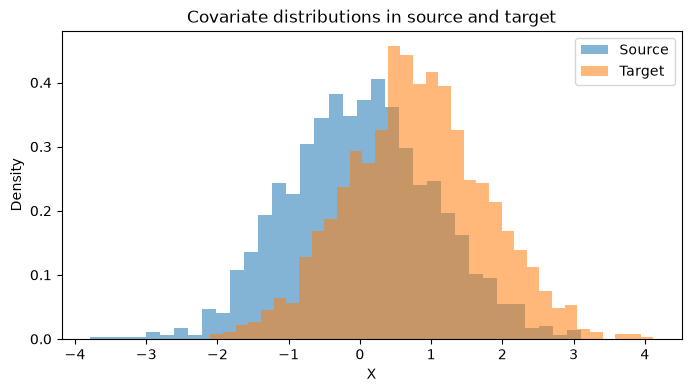

In [4]:
def simulate_domain(n, delta, domain, rng):
    mu = 0.0 if domain == 'source' else delta
    x = rng.normal(mu, 1.0, n)
    treatment = rng.binomial(1, 0.5, n)
    noise = rng.normal(0.0, 1.0, n)
    y = 1.0 + 0.5*x + treatment*(2.0 + 1.5*x) + noise
    return pd.DataFrame({'x': x, 'treatment': treatment, 'y': y})

def true_ate(delta):
    return 2.0 + 1.5*delta

rng = np.random.default_rng(SEED)
source = simulate_domain(N_SOURCE, DELTA, 'source', rng)
target = simulate_domain(N_TARGET, DELTA, 'target', rng)
print('Source ATE:', true_ate(0.0))
print('Target ATE:', true_ate(DELTA))
fig, ax = plt.subplots(figsize=(8, 4))
ax.hist(source['x'], bins=35, alpha=0.55, density=True, label='Source')
ax.hist(target['x'], bins=35, alpha=0.55, density=True, label='Target')
ax.set(title='Covariate distributions in source and target', xlabel='X', ylabel='Density')
ax.legend(); plt.show()


## 2. Three estimators

1. **Naive source ATE:** treated mean minus control mean in the source. It estimates the source estimand, which can differ from the target estimand.
2. **Outcome standardization:** fit a model with `X`, `T`, and `T × X` in the source, predict outcomes under both treatment states for target participants, then average the individual predicted contrasts.
3. **Importance weighting:** weight source participants by the density ratio `p_target(X)/p_source(X)`. Here this ratio is known from the simulation. In real data, it would generally need to be estimated.

In [5]:
def naive_source_ate(source):
    return (source.loc[source.treatment == 1, 'y'].mean()
            - source.loc[source.treatment == 0, 'y'].mean())

def standardized_target_ate(source, target):
    x, t = source['x'].to_numpy(), source['treatment'].to_numpy()
    design = pd.DataFrame({'intercept': np.ones(len(source)), 'x': x,
                           'treatment': t, 'treatment_x': t*x})
    model = sm.OLS(source['y'].to_numpy(), design).fit()
    xt = target['x'].to_numpy()
    d1 = pd.DataFrame({'intercept': np.ones(len(target)), 'x': xt,
                       'treatment': np.ones(len(target)), 'treatment_x': xt})
    d0 = pd.DataFrame({'intercept': np.ones(len(target)), 'x': xt,
                       'treatment': np.zeros(len(target)), 'treatment_x': np.zeros(len(target))})
    return float(np.mean(model.predict(d1) - model.predict(d0)))

def importance_weighted_ate(source, delta):
    x = source['x'].to_numpy()
    t = source['treatment'].to_numpy()
    y = source['y'].to_numpy()
    w = np.exp(delta*x - 0.5*delta**2)  # target/source density ratio
    treated, control = t == 1, t == 0
    mu1 = np.sum(w[treated]*y[treated]) / np.sum(w[treated])
    mu0 = np.sum(w[control]*y[control]) / np.sum(w[control])
    return float(mu1 - mu0)

print('Naive source:', naive_source_ate(source))
print('Standardized target:', standardized_target_ate(source, target))
print('Importance weighted:', importance_weighted_ate(source, DELTA))
print('True target ATE:', true_ate(DELTA))


Naive source: 2.0451008745511694
Standardized target: 3.2332814098271156
Importance weighted: 3.338770063244808
True target ATE: 3.2


## 3. Repeated simulation and evaluation

We repeat the experiment and calculate bias, standard deviation, and root mean squared error (RMSE) relative to the **target ATE**. The naive source estimator is expected to be centered around the source ATE, so its error for the target estimand reflects the transportability problem.

,bias,sd,rmse
method,,,
Outcome standardization,0.001,0.073,0.073
Importance weighting,-0.006,0.146,0.146
Naive source ATE,-1.202,0.091,1.205


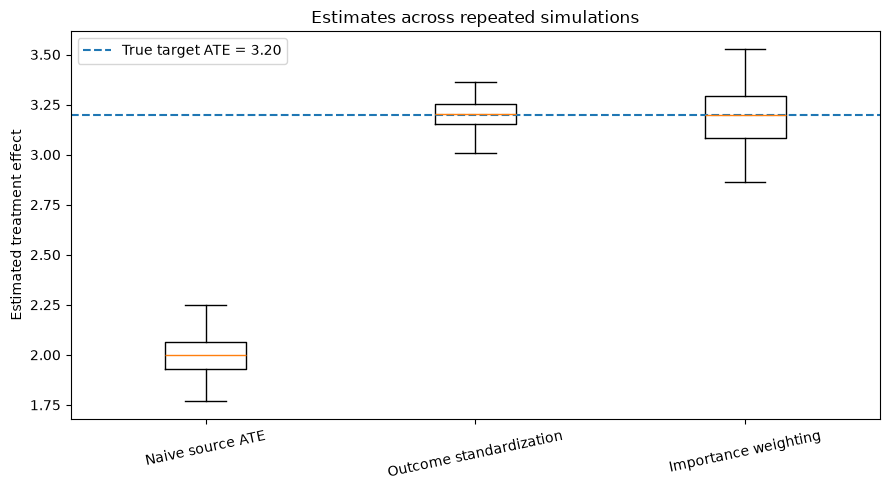

In [6]:
def run_simulation(n_repeats=300, n_source=1500, n_target=1500, delta=0.8, seed=SEED):
    rng = np.random.default_rng(seed)
    truth = true_ate(delta)
    rows = []
    for r in range(n_repeats):
        src = simulate_domain(n_source, delta, 'source', rng)
        tgt = simulate_domain(n_target, delta, 'target', rng)
        estimates = {
            'Naive source ATE': naive_source_ate(src),
            'Outcome standardization': standardized_target_ate(src, tgt),
            'Importance weighting': importance_weighted_ate(src, delta),
        }
        for method, estimate in estimates.items():
            rows.append({'repetition': r, 'method': method, 'estimate': estimate,
                         'target_truth': truth, 'error': estimate-truth})
    return pd.DataFrame(rows)

results = run_simulation()
summary = results.groupby('method')['error'].agg(
    bias='mean', sd='std', rmse=lambda e: np.sqrt(np.mean(e**2))
).sort_values('rmse')
display(summary.round(3))

fig, ax = plt.subplots(figsize=(9, 5))
methods = list(results['method'].drop_duplicates())
ax.boxplot([results.loc[results.method == m, 'estimate'] for m in methods],
           tick_labels=methods, showfliers=False)
ax.axhline(true_ate(DELTA), linestyle='--', label=f'True target ATE = {true_ate(DELTA):.2f}')
ax.set_ylabel('Estimated treatment effect')
ax.set_title('Estimates across repeated simulations')
ax.tick_params(axis='x', rotation=12)
ax.legend(); plt.tight_layout(); plt.show()


## 4. How does performance change as the domains separate?

We vary `delta`, the difference in the means of the source and target covariate distributions. Larger shifts can make importance weights more variable and can challenge transportability in finite samples.

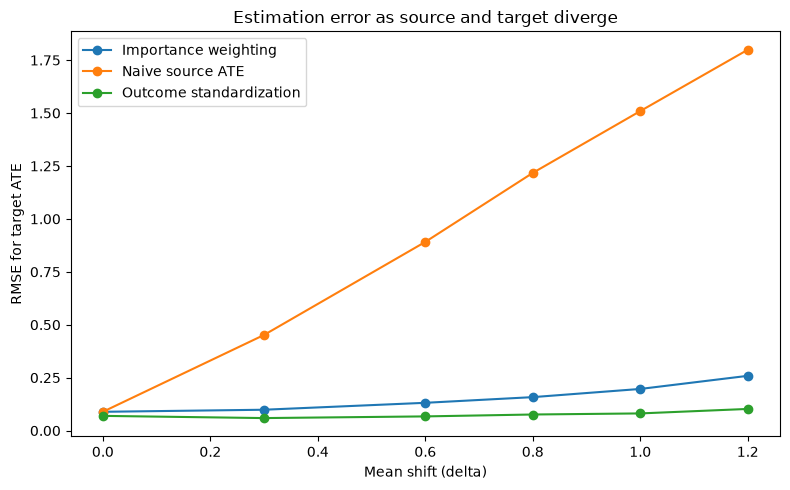

In [7]:
shift_rows = []
for delta in [0.0, 0.3, 0.6, 0.8, 1.0, 1.2]:
    res = run_simulation(n_repeats=150, n_source=1500, n_target=1500,
                         delta=delta, seed=SEED + int(delta*1000) + 1)
    summ = res.groupby('method')['error'].agg(
        bias='mean', rmse=lambda e: np.sqrt(np.mean(e**2))
    ).reset_index()
    summ['delta'] = delta
    shift_rows.append(summ)
by_shift = pd.concat(shift_rows, ignore_index=True)

fig, ax = plt.subplots(figsize=(8, 5))
for method, part in by_shift.groupby('method'):
    ax.plot(part['delta'], part['rmse'], marker='o', label=method)
ax.set(xlabel='Mean shift (delta)', ylabel='RMSE for target ATE',
       title='Estimation error as source and target diverge')
ax.legend(); plt.tight_layout(); plt.show()


## 5. Interpretation and limitations

Use the outputs to answer:

- Does the naive source ATE estimate the target ATE when treatment effects are heterogeneous?
- Does outcome standardization recover the target effect under this correctly specified model?
- How does importance weighting behave as `delta` increases?
- What is the role of overlap between source and target covariate distributions?

**Limitations:** the data are simulated; treatment is randomized; the density ratio is known; the outcome model is correctly specified; and no formal generalization bound is proved. The next extension could add an incorrect outcome model, estimated density ratios, or a mechanism-shift scenario.